# Lecture 3 — Class Exercise
## Line Charts: CO2 Emissions

> **Push to:** `week03/lecture03_exercise.ipynb` in your GitHub repo

### Remember:
- No spaghetti — if you show multiple lines, grey everything and highlight one
- Remove chart borders, heavy gridlines, rotating text
- Label directly; avoid legends where possible
- Insight title


In [7]:
!pip install numpy

In [1]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# Dataset: CO2 Emissions by Country 2000-2022
# Source: Our World in Data (https://ourworldindata.org/co2-emissions)
df = pd.read_csv('co2_emissions.csv')
print(f"Loaded: {len(df)} rows | Countries: {df['Country'].nunique()} | Years: {df['Year'].min()}-{df['Year'].max()}")
print(df.head())


Loaded: 345 rows | Countries: 15 | Years: 2000-2022
         Country         Region  Year  CO2_Mt  CO2_per_capita
0  United States  North America  2000  5857.6            1.32
1  United States  North America  2001  5724.0            1.26
2  United States  North America  2002  5652.8            1.11
3  United States  North America  2003  5592.8            1.29
4  United States  North America  2004  5743.2            1.12


In [2]:
# Explore before building

print("Countries:", df['Country'].unique())
print("\nCO2 range:", df['CO2_Mt'].min(), "to", df['CO2_Mt'].max(), "Mt")
print("\nRegional averages (2022):")
print(df[df['Year']==2022].groupby('Region')['CO2_Mt'].mean().sort_values(ascending=False).round(1))


Countries: <StringArray>
[ 'United States',          'China',          'India',        'Germany',
 'United Kingdom',         'France',         'Brazil',          'Japan',
         'Canada',      'Australia',    'South Korea',         'Russia',
   'South Africa',         'Mexico',      'Indonesia']
Length: 15, dtype: str

CO2 range: 125.3 to 12409.5 Mt

Regional averages (2022):
Region
Asia             3531.1
North America    2393.8
Latin America     629.2
Africa            534.4
Europe            496.5
Oceania           493.7
Name: CO2_Mt, dtype: float64


---
## Task — Multi-Series Line Chart with Highlight

**What to build:** A line chart showing CO2 emissions over time for **all Asian countries** in the dataset, with one country highlighted.

**Requirements:**
- All countries shown (for context), but only **one highlighted in colour** — your choice which
- All other lines in grey (#EEEEEE), thinner
- Highlighted country **labelled directly** at the end of its line (not in a legend)
- Insight title that names the highlighted country and its story

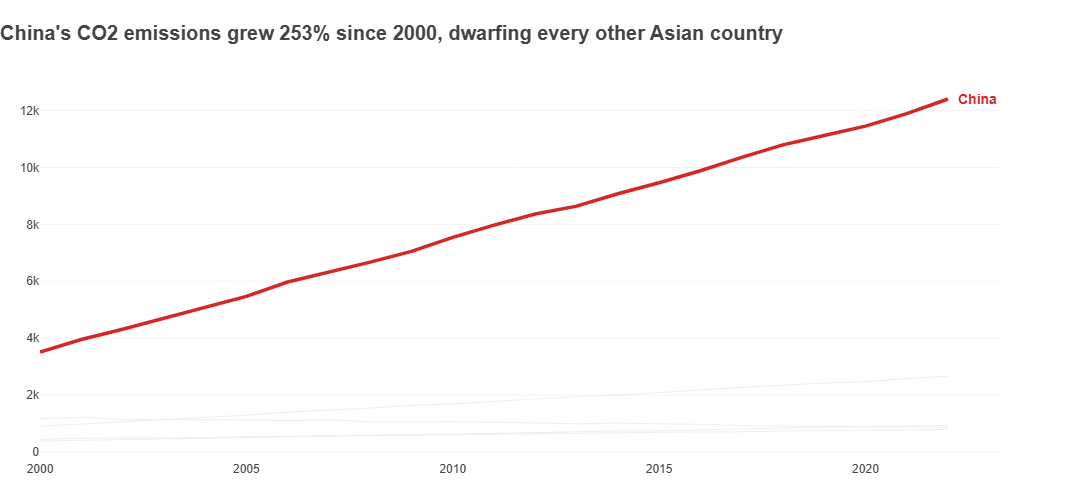

In [3]:
# Task — Multi-series line with highlight
# Task — Multi-series line with highlight
HIGHLIGHT = 'China'
HIGHLIGHT_COLOR = '#D62728'
GREY = '#EEEEEE'

asia = df[df['Region'] == 'Asia'].sort_values(['Country', 'Year'])

# Insight numbers computed from the data so the title stays accurate
hl = asia[asia['Country'] == HIGHLIGHT]
start, end = hl.iloc[0], hl.iloc[-1]
growth = (end['CO2_Mt'] / start['CO2_Mt'] - 1) * 100

fig = go.Figure()

# 1) Context lines: all other Asian countries, grey and thin
for country, g in asia[asia['Country'] != HIGHLIGHT].groupby('Country'):
    fig.add_trace(go.Scatter(
        x=g['Year'], y=g['CO2_Mt'], mode='lines',
        line=dict(color=GREY, width=1),
        hoverinfo='skip', showlegend=False
    ))

# 2) Highlighted line drawn on top
fig.add_trace(go.Scatter(
    x=hl['Year'], y=hl['CO2_Mt'], mode='lines',
    line=dict(color=HIGHLIGHT_COLOR, width=3.5),
    showlegend=False
))

# 3) Direct label at the end of the highlighted line (no legend)
fig.add_annotation(
    x=end['Year'], y=end['CO2_Mt'],
    text=f"<b>{HIGHLIGHT}</b>",
    showarrow=False, xanchor='left', xshift=8,
    font=dict(color=HIGHLIGHT_COLOR, size=14)
)

fig.update_layout(
    title=dict(
        text=f"<b>{HIGHLIGHT}'s CO2 emissions grew {growth:.0f}% since {int(start['Year'])}, "
             f"dwarfing every other Asian country</b>",
        x=0, xanchor='left', font=dict(size=20)
    ),
    plot_bgcolor='white', paper_bgcolor='white',
    showlegend=False,
    margin=dict(l=40, r=90, t=80, b=40),
    width=900, height=500,
    font=dict(family='Arial', color='#444444')
)

# No axis titles, no borders, light gridlines, horizontal tick labels
fig.update_xaxes(
    title=None, showgrid=False, showline=False, zeroline=False,
    tickangle=0, dtick=5
)
fig.update_yaxes(
    title=None, showgrid=True, gridcolor='#F2F2F2', gridwidth=1,
    showline=False, zeroline=False
)

fig.show()
